<a href="https://colab.research.google.com/github/ntanphu/ML-HK261/blob/main/introduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Chapter 1 — Introduction
Notebook minh họa cấu trúc dữ liệu phi tuyến và hướng tiếp cận của Diffusion Maps.

In [ ]:
!git clone https://github.com/ntanphu/ML-HK261.git
%cd /content/ML-HK261

fatal: destination path 'ML-HK261' already exists and is not an empty directory.
/content/ML-HK261


In [ ]:
!ls -la pictures

-rw-r--r-- 1 root root 1 Nov 19 05:18 pictures


---
## 1.1 Minh họa cấu trúc đa tạp phi tuyến

Khởi tạo $n=1800$ điểm Swiss Roll và trực quan hóa tọa độ ba chiều cùng tọa độ nội tại hai chiều. Qua đó minh họa sự khác biệt giữa số chiều biểu diễn và số chiều nội tại.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from sklearn.datasets import make_swiss_roll

# ---------- Publication style ----------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",

    "font.size": 8.5,
    "axes.labelsize": 9.0,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,

    "axes.linewidth": 0.75,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.65,
    "ytick.major.width": 0.65,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,

    # Embed fonts in PDF
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

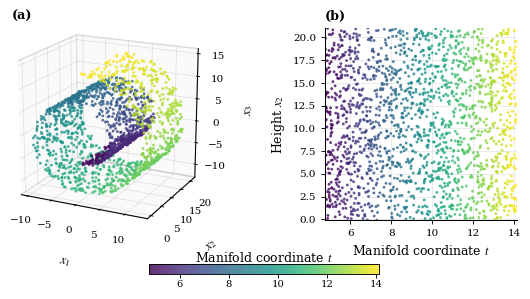

Saved PDF: /content/pictures/fig1_1_swiss_roll.pdf
Saved PNG: /content/pictures/fig1_1_swiss_roll.png


In [ ]:
# ============================================================
# Swiss Roll -- Generate data
# ============================================================
n = 1800

X_roll, t_roll = make_swiss_roll(
    n_samples=n,
    noise=0.10,
    random_state=42
)

norm = Normalize(
    vmin=float(t_roll.min()),
    vmax=float(t_roll.max())
)

# ---------- Figure layout ----------
# Compact figure suitable for a two-column paper.
fig = plt.figure(figsize=(6.4, 2.9))

# Two panels with exactly the same physical dimensions.
left_panel  = [0.105, 0.25, 0.30, 0.662]
right_panel = [0.595, 0.25, 0.30, 0.662]

ax1 = fig.add_axes(left_panel, projection="3d")
ax2 = fig.add_axes(right_panel)

scatter_style = {
    "cmap": "viridis",
    "norm": norm,
    "s": 4.2,
    "alpha": 0.82,
    "linewidths": 0,
    "rasterized": True,
}

# ---------- Panel (a): ambient 3D space ----------
sc1 = ax1.scatter(
    X_roll[:, 0],
    X_roll[:, 1],
    X_roll[:, 2],
    c=t_roll,
    depthshade=False,
    **scatter_style
)

# The zoom argument is supported by current Google Colab Matplotlib.
try:
    ax1.set_box_aspect((1.0, 0.88, 1.0), zoom=1.16)
except TypeError:
    # Compatibility fallback for older Matplotlib versions.
    ax1.set_box_aspect((1.0, 0.88, 1.0))

ax1.view_init(elev=18, azim=-64)

ax1.set_xlabel(r"$x_1$", labelpad=1.5)
ax1.set_ylabel(r"$x_2$", labelpad=1.5)
ax1.set_zlabel(r"$x_3$", labelpad=1.5)
ax1.tick_params(pad=0.5)

# Light 3D panes and grid.
for axis in (ax1.xaxis, ax1.yaxis, ax1.zaxis):
    axis.pane.fill = True
    axis.pane.set_facecolor((0.97, 0.97, 0.97, 1.0))
    axis.pane.set_edgecolor((0.72, 0.72, 0.72, 1.0))
    axis._axinfo["grid"].update({
        "color": (0.55, 0.55, 0.55, 0.28),
        "linewidth": 0.45,
    })

# ---------- Panel (b): intrinsic coordinates ----------
ax2.scatter(
    t_roll,
    X_roll[:, 1],
    c=t_roll,
    **scatter_style
)

ax2.set_xlabel(r"Manifold coordinate $t$")
ax2.set_ylabel(r"Height $x_2$")

# Make panel (b) physically square like panel (a).
ax2.set_box_aspect(1.0)

ax2.set_xlim(float(t_roll.min()), float(t_roll.max()))
ax2.set_ylim(
    float(X_roll[:, 1].min()),
    float(X_roll[:, 1].max())
)

ax2.grid(
    True,
    color="0.84",
    linewidth=0.45,
    alpha=0.80
)
ax2.set_axisbelow(True)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

# ---------- Panel labels ----------
# Labels are outside the plotting regions, preventing overlap.
fig.text(
    left_panel[0],
    0.93,
    "(a)",
    ha="left",
    va="bottom",
    fontsize=9.2,
    fontweight="bold"
)

fig.text(
    right_panel[0],
    0.93,
    "(b)",
    ha="left",
    va="bottom",
    fontsize=9.2,
    fontweight="bold"
)

# ---------- Shared colorbar ----------
cbar_ax = fig.add_axes([0.32, 0.065, 0.36, 0.032])

cbar = fig.colorbar(
    sc1,
    cax=cbar_ax,
    orientation="horizontal"
)

# Put the label above the colorbar to avoid bottom clipping.
cbar.ax.xaxis.set_label_position("top")
cbar.set_label(
    r"Manifold coordinate $t$",
    labelpad=2.0
)
cbar.ax.tick_params(labelsize=7.2, pad=1.5)
cbar.outline.set_linewidth(0.65)

# ---------- Save outputs ----------
output_dir = "/content/pictures"
os.makedirs(output_dir, exist_ok=True)

pdf_path = os.path.join(output_dir, "fig1_1_swiss_roll.pdf")
png_path = os.path.join(output_dir, "fig1_1_swiss_roll.png")

# Do not use bbox_inches="tight"; it can recrop the canvas
# and make the two panels appear asymmetrical.
fig.savefig(
    pdf_path,
    dpi=600,
    bbox_inches=None,
    pad_inches=0
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches=None,
    pad_inches=0
)

plt.show()

print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)

---
## 1.2 Hệ động lực Lorenz

Mô phỏng hệ Lorenz với $\sigma=10$, $\rho=28$ và $\beta=8/3$ để minh họa cấu trúc phi tuyến của quỹ đạo trong không gian pha.

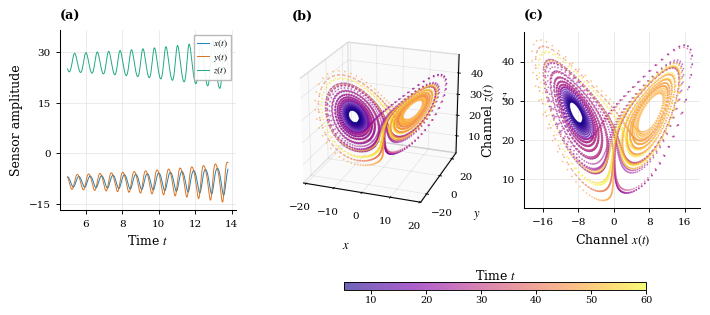

Saved PDF: /content/pictures/fig1_2_sensor_lorenz.pdf
Saved PNG: /content/pictures/fig1_2_sensor_lorenz.png


In [ ]:

# ============================================================
# Figure 1.2 — Lorenz sensor stream
# Compact three-panel layout for Google Colab
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from matplotlib.colors import Normalize
from scipy.integrate import solve_ivp

# ------------------------------------------------------------
# 2. Lorenz system
# ------------------------------------------------------------
def lorenz_system(t, state, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = state

    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z

    return [dx, dy, dz]


sol = solve_ivp(
    lorenz_system,
    t_span=(0.0, 60.0),
    y0=[1.0, 0.0, 0.0],
    method="DOP853",
    t_eval=np.linspace(5.0, 60.0, 5000),
    rtol=1e-10,
    atol=1e-12
)

if not sol.success:
    raise RuntimeError(sol.message)

t_lor = sol.t
X_lor = sol.y.T

# Time is kept in physical units rather than normalised units.
time_norm = Normalize(
    vmin=float(t_lor.min()),
    vmax=float(t_lor.max())
)

# Colour-blind-friendly line colours.
channel_colors = [
    "#0072B2",  # blue
    "#D55E00",  # vermilion
    "#009E73",  # green
]

channel_labels = [
    r"$x(t)$",
    r"$y(t)$",
    r"$z(t)$",
]


# ------------------------------------------------------------
# 3. Figure layout
# ------------------------------------------------------------
# Full-width but compact figure.
fig = plt.figure(figsize=(7.2, 3.0))

# All three panels have exactly the same width and height.
panel_a = [0.0550, 0.32, 0.245, 0.60]
panel_b = [0.3775, 0.32, 0.245, 0.60]
panel_c = [0.7000, 0.32, 0.245, 0.60]

ax_ts = fig.add_axes(panel_a)
ax_3d = fig.add_axes(panel_b, projection="3d")
ax_2d = fig.add_axes(panel_c)


# ------------------------------------------------------------
# 4. Panel (a): multivariate sensor stream
# ------------------------------------------------------------
n_show = 800

for channel, color, label in zip(
    range(3),
    channel_colors,
    channel_labels
):
    ax_ts.plot(
        t_lor[:n_show],
        X_lor[:n_show, channel],
        color=color,
        linewidth=0.70,
        alpha=0.88,
        label=label
    )

ax_ts.set_xlabel(r"Time $t$")
ax_ts.set_ylabel("Sensor amplitude")

ax_ts.yaxis.set_major_locator(
    ticker.MaxNLocator(nbins=5)
)
ax_ts.xaxis.set_major_locator(
    ticker.MaxNLocator(nbins=5)
)

ax_ts.grid(
    True,
    color="0.86",
    linewidth=0.45,
    alpha=0.85
)
ax_ts.set_axisbelow(True)

ax_ts.spines["top"].set_visible(False)
ax_ts.spines["right"].set_visible(False)

ax_ts.legend(
    loc="upper right",
    ncol=1,
    frameon=True,
    fancybox=False,
    framealpha=0.92,
    edgecolor="0.70",
    facecolor="white",
    handlelength=1.25,
    handletextpad=0.45,
    borderpad=0.35,
    labelspacing=0.25
)


# ------------------------------------------------------------
# 5. Panel (b): 3D Lorenz attractor
# ------------------------------------------------------------
scatter_style = {
    "cmap": "plasma",
    "norm": time_norm,
    "s": 1.6,
    "alpha": 0.62,
    "linewidths": 0,
    "rasterized": True,
}

sc_3d = ax_3d.scatter(
    X_lor[:, 0],
    X_lor[:, 1],
    X_lor[:, 2],
    c=t_lor,
    depthshade=False,
    **scatter_style
)

# Match the apparent size of the 3D attractor to the other panels.
try:
    ax_3d.set_box_aspect(
        (1.0, 1.0, 0.90),
        zoom=1.12
    )
except TypeError:
    ax_3d.set_box_aspect((1.0, 1.0, 0.90))

ax_3d.view_init(elev=22, azim=290)

ax_3d.set_xlabel(r"$x$", labelpad=1.0)
ax_3d.set_ylabel(r"$y$", labelpad=1.0)
ax_3d.set_zlabel(r"$z$", labelpad=1.0)
ax_3d.tick_params(pad=0.3)

# Light background panes.
for axis in (ax_3d.xaxis, ax_3d.yaxis, ax_3d.zaxis):
    axis.pane.fill = True
    axis.pane.set_facecolor((0.97, 0.97, 0.97, 1.0))
    axis.pane.set_edgecolor((0.74, 0.74, 0.74, 1.0))
    axis._axinfo["grid"].update({
        "color": (0.55, 0.55, 0.55, 0.25),
        "linewidth": 0.40,
    })


# ------------------------------------------------------------
# 6. Panel (c): x-z projection
# ------------------------------------------------------------
ax_2d.scatter(
    X_lor[:, 0],
    X_lor[:, 2],
    c=t_lor,
    **scatter_style
)

ax_2d.set_xlabel(r"Channel $x(t)$")
ax_2d.set_ylabel(r"Channel $z(t)$")

# Keep the physical plotting area equal to the other panels.
ax_2d.set_box_aspect(1.0)

ax_2d.xaxis.set_major_locator(
    ticker.MaxNLocator(nbins=5)
)
ax_2d.yaxis.set_major_locator(
    ticker.MaxNLocator(nbins=5)
)

ax_2d.grid(
    True,
    color="0.86",
    linewidth=0.45,
    alpha=0.85
)
ax_2d.set_axisbelow(True)

ax_2d.spines["top"].set_visible(False)
ax_2d.spines["right"].set_visible(False)


# ------------------------------------------------------------
# 7. Panel labels outside the data regions
# ------------------------------------------------------------
panel_label_style = {
    "ha": "left",
    "va": "bottom",
    "fontsize": 9.2,
    "fontweight": "bold",
}

fig.text(panel_a[0], 0.945, "(a)", **panel_label_style)
fig.text(panel_b[0], 0.945, "(b)", **panel_label_style)
fig.text(panel_c[0], 0.945, "(c)", **panel_label_style)


# ------------------------------------------------------------
# 8. Shared colorbar for panels (b) and (c)
# ------------------------------------------------------------
cbar_ax = fig.add_axes([
    0.450,   # left
    0.055,   # bottom
    0.420,   # width
    0.025    # height
])

cbar = fig.colorbar(
    sc_3d,
    cax=cbar_ax,
    orientation="horizontal"
)

# Place label above colorbar to prevent bottom clipping.
cbar.ax.xaxis.set_label_position("top")
cbar.set_label(r"Time $t$", labelpad=2.0)

cbar.ax.tick_params(
    labelsize=7.0,
    pad=1.5
)
cbar.outline.set_linewidth(0.65)


# ------------------------------------------------------------
# 9. Save outputs
# ------------------------------------------------------------
output_dir = "/content/pictures"
os.makedirs(output_dir, exist_ok=True)

pdf_path = os.path.join(
    output_dir,
    "fig1_2_sensor_lorenz.pdf"
)

png_path = os.path.join(
    output_dir,
    "fig1_2_sensor_lorenz.png"
)

# Avoid bbox_inches="tight" because the 3D labels can cause
# asymmetric recropping of the three-panel layout.
fig.savefig(
    pdf_path,
    dpi=600,
    bbox_inches=None,
    pad_inches=0
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches=None,
    pad_inches=0
)

plt.show()

print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)


---
## 1.3 Phương pháp giảm chiều PCA
Áp dụng PCA trên dữ liệu phân cụm tổng hợp để trực quan hóa các hướng phương sai chủ đạo và tỷ lệ phương sai giải thích.



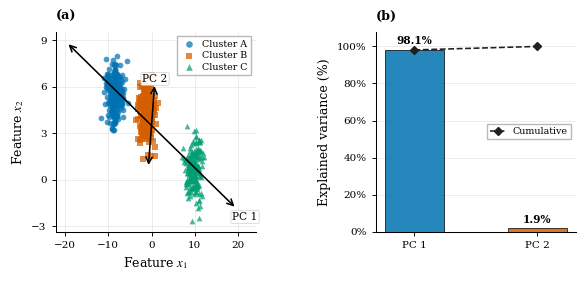

Two principal components retain 100.0% of the total variance.
Saved PDF: /content/pictures/fig1_3_pca_linear.pdf
Saved PNG: /content/pictures/fig1_3_pca_linear.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA

CB = {"blue": "#0072B2", "red": "#D55E00", "green": "#009E73", "black": "#202020"}

X_blobs, y_blobs = make_blobs(n_samples=600, centers=3, cluster_std=1.05, random_state=7)
pca_2d = PCA(n_components=2)
X_pca2 = pca_2d.fit_transform(X_blobs)
varexp = pca_2d.explained_variance_ratio_
cumvar = np.cumsum(varexp)

CL_COLORS = [CB["blue"], CB["red"], CB["green"]]
CL_MARKERS = ["o", "s", "^"]
CL_NAMES = ["Cluster A", "Cluster B", "Cluster C"]

fig = plt.figure(figsize=(6.4, 2.9))
panel_a = [0.094, 0.205, 0.3125, 0.690]
panel_b = [0.594, 0.205, 0.3125, 0.690]
ax_data = fig.add_axes(panel_a)
ax_var = fig.add_axes(panel_b)

for k in range(3):
    mask = y_blobs == k
    ax_data.scatter(X_blobs[mask, 0], X_blobs[mask, 1], color=CL_COLORS[k], marker=CL_MARKERS[k], s=17, alpha=0.72, linewidths=0, label=CL_NAMES[k], zorder=3)

mu = X_blobs.mean(axis=0)
display_points = [X_blobs]

for component, eigenvalue, label in zip(pca_2d.components_, pca_2d.explained_variance_, ["PC 1", "PC 2"]):
    scale = 2.6 * np.sqrt(eigenvalue)
    point_minus = mu - scale * component
    point_plus = mu + scale * component
    label_point = mu + 1.10 * scale * component
    ax_data.annotate("", xy=point_plus, xytext=point_minus, arrowprops={"arrowstyle": "<->", "color": "black", "linewidth": 1.15, "mutation_scale": 11}, zorder=5)
    ax_data.text(label_point[0], label_point[1], label, ha="center", va="center", fontsize=7.6, zorder=6, bbox={"boxstyle": "round,pad=0.14", "facecolor": "white", "edgecolor": "0.75", "linewidth": 0.4, "alpha": 0.90})
    display_points.extend([point_minus[np.newaxis, :], point_plus[np.newaxis, :], label_point[np.newaxis, :]])

display_points = np.vstack(display_points)
x_margin = 0.06 * np.ptp(display_points[:, 0])
y_margin = 0.06 * np.ptp(display_points[:, 1])

ax_data.set_xlim(display_points[:, 0].min() - x_margin, display_points[:, 0].max() + x_margin)
ax_data.set_ylim(display_points[:, 1].min() - y_margin, display_points[:, 1].max() + y_margin)
ax_data.set_xlabel(r"Feature $x_1$")
ax_data.set_ylabel(r"Feature $x_2$")
ax_data.set_box_aspect(1.0)
ax_data.grid(True, color="0.86", linewidth=0.45, alpha=0.80)
ax_data.set_axisbelow(True)
ax_data.spines["top"].set_visible(False)
ax_data.spines["right"].set_visible(False)
ax_data.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax_data.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax_data.legend(loc="best", frameon=True, fancybox=False, framealpha=0.92, edgecolor="0.70", facecolor="white", markerscale=1.15, handletextpad=0.35, borderpad=0.35, labelspacing=0.25)

pc_labels = [f"PC {i + 1}" for i in range(len(varexp))]
bar_colors = [CB["blue"], CB["red"]]
bars = ax_var.bar(pc_labels, varexp * 100, width=0.48, color=bar_colors, edgecolor="black", linewidth=0.60, alpha=0.85, zorder=3)

for bar, value in zip(bars, varexp):
    ax_var.text(bar.get_x() + bar.get_width() / 2, value * 100 + 2.0, f"{value * 100:.1f}%", ha="center", va="bottom", fontsize=7.6, fontweight="bold", zorder=5)

ax_var.plot(pc_labels, cumvar * 100, color=CB["black"], linestyle="--", marker="D", markersize=4.2, linewidth=1.15, label="Cumulative", zorder=4)
ax_var.set_ylabel("Explained variance (%)")
ax_var.set_ylim(0, 108)
ax_var.set_box_aspect(1.0)
ax_var.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100, decimals=0))
ax_var.yaxis.set_major_locator(ticker.MultipleLocator(20))
ax_var.grid(True, axis="y", color="0.86", linewidth=0.45, alpha=0.80)
ax_var.set_axisbelow(True)
ax_var.spines["top"].set_visible(False)
ax_var.spines["right"].set_visible(False)
ax_var.legend(loc="center right", frameon=True, fancybox=False, framealpha=0.92, edgecolor="0.70", facecolor="white", handlelength=1.6, borderpad=0.35)

panel_label_style = {"ha": "left", "va": "bottom", "fontsize": 9.2, "fontweight": "bold"}
fig.text(panel_a[0], 0.925, "(a)", **panel_label_style)
fig.text(panel_b[0], 0.925, "(b)", **panel_label_style)

output_dir = "/content/pictures"
os.makedirs(output_dir, exist_ok=True)
pdf_path = os.path.join(output_dir, "fig1_3_pca_linear.pdf")
png_path = os.path.join(output_dir, "fig1_3_pca_linear.png")

fig.savefig(pdf_path, dpi=600, bbox_inches=None, pad_inches=0)
fig.savefig(png_path, dpi=600, bbox_inches=None, pad_inches=0)
plt.show()

print(f"Two principal components retain {cumvar[-1] * 100:.1f}% of the total variance.")
print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)

---

## 1.3. Hạn chế của PCA đối với cấu trúc phi tuyến

PCA là phương pháp giảm chiều **tuyến tính**, nhằm bảo toàn tối đa phương sai của dữ liệu. Khi áp dụng trên dữ liệu có cấu trúc phi tuyến, PCA có thể:

- Làm sai lệch quan hệ lân cận.
- Làm mờ thông tin chuyển tiếp giữa các trạng thái.
- Gây chồng lấn các cấu trúc cục bộ.
- Làm giảm khả năng phân cụm và phân tách lớp.

Hình dưới minh họa hạn chế của PCA trên bộ dữ liệu **MNIST**. Phép chiếu từ 784 chiều xuống hai chiều có thể gây chồng lấn giữa các nhóm chữ số. Điều này cho thấy hạn chế của PCA trong việc bảo toàn cấu trúc phi tuyến và đặc trưng phân biệt giữa các lớp.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


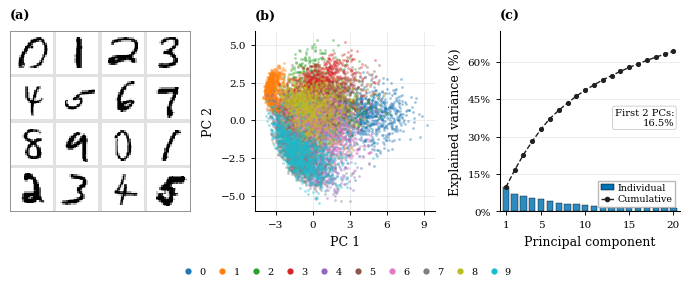

Variance retained by the first two PCs: 16.49%
Saved PDF: /content/pictures/fig1_4_pca_mnist.pdf
Saved PNG: /content/pictures/fig1_4_pca_mnist.png


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from tensorflow.keras.datasets import mnist

(x_train, y_train), (_, _) = mnist.load_data()

rng = np.random.default_rng(42)
samples_per_class = 1000
selected_indices = np.concatenate([rng.choice(np.flatnonzero(y_train == digit), samples_per_class, replace=False) for digit in range(10)])
rng.shuffle(selected_indices)

X_images = x_train[selected_indices]
y_mnist = y_train[selected_indices]
X_mnist = X_images.reshape(len(X_images), 784).astype(np.float32) / 255.0

pca_mnist = PCA(n_components=50, svd_solver="randomized", random_state=42)
X_mnist_pca = pca_mnist.fit_transform(X_mnist)
varexp = pca_mnist.explained_variance_ratio_
cumvar = np.cumsum(varexp)
variance_2d = cumvar[1] * 100

DIGIT_COLORS = plt.cm.tab10(np.arange(10))
fig = plt.figure(figsize=(7.2, 3.0))

panel_a = [0.035, 0.270, 0.250, 0.600]
panel_b = [0.375, 0.270, 0.250, 0.600]
panel_c = [0.715, 0.270, 0.250, 0.600]

ax_img = fig.add_axes(panel_a)
ax_pca = fig.add_axes(panel_b)
ax_var = fig.add_axes(panel_c)

grid_size = 4
tile_size = 28
gap = 2
canvas_size = grid_size * tile_size + (grid_size - 1) * gap
montage = np.full((canvas_size, canvas_size), 0.12, dtype=float)

montage_indices = [np.flatnonzero(y_mnist == digit)[0] for digit in range(10)]
montage_indices += [np.flatnonzero(y_mnist == digit)[1] for digit in range(6)]

for position, sample_index in enumerate(montage_indices):
    row, col = divmod(position, grid_size)
    row_start = row * (tile_size + gap)
    col_start = col * (tile_size + gap)
    montage[row_start:row_start + tile_size, col_start:col_start + tile_size] = X_images[sample_index].astype(float) / 255.0

ax_img.imshow(montage, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
ax_img.set_box_aspect(1.0)
ax_img.set_xticks([])
ax_img.set_yticks([])

for spine in ax_img.spines.values():
    spine.set_color("0.55")
    spine.set_linewidth(0.65)

for digit in range(10):
    mask = y_mnist == digit
    ax_pca.scatter(X_mnist_pca[mask, 0], X_mnist_pca[mask, 1], color=DIGIT_COLORS[digit], s=4.0, alpha=0.42, linewidths=0, rasterized=True, zorder=3)

ax_pca.set_xlabel("PC 1")
ax_pca.set_ylabel("PC 2")
ax_pca.set_box_aspect(1.0)
ax_pca.grid(True, color="0.86", linewidth=0.45, alpha=0.80)
ax_pca.set_axisbelow(True)
ax_pca.spines["top"].set_visible(False)
ax_pca.spines["right"].set_visible(False)
ax_pca.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax_pca.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5))

n_components_show = 20
pc_numbers = np.arange(1, n_components_show + 1)
bar_values = varexp[:n_components_show] * 100
cumulative_values = cumvar[:n_components_show] * 100

ax_var.bar(pc_numbers, bar_values, color="#0072B2", edgecolor="black", linewidth=0.35, width=0.72, alpha=0.82, zorder=3)
ax_var.plot(pc_numbers, cumulative_values, color="#202020", linestyle="--", marker="o", markersize=2.7, linewidth=1.0, zorder=4)
ax_var.set_xlabel("Principal component")
ax_var.set_ylabel("Explained variance (%)")
ax_var.set_box_aspect(1.0)
ax_var.set_xticks([1, 5, 10, 15, 20])
ax_var.set_xlim(0.3, 20.7)
ax_var.set_ylim(0, min(100, cumulative_values[-1] + 8))
ax_var.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100, decimals=0))
ax_var.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax_var.grid(True, axis="y", color="0.86", linewidth=0.45, alpha=0.80)
ax_var.set_axisbelow(True)
ax_var.spines["top"].set_visible(False)
ax_var.spines["right"].set_visible(False)

variance_handles = [Patch(facecolor="#0072B2", edgecolor="black", linewidth=0.35, label="Individual"), Line2D([0], [0], color="#202020", linestyle="--", marker="o", markersize=3, linewidth=1.0, label="Cumulative")]
ax_var.legend(handles=variance_handles, loc="lower right", frameon=True, fancybox=False, framealpha=0.92, edgecolor="0.70", facecolor="white", handlelength=1.4, handletextpad=0.35, borderpad=0.30, labelspacing=0.25)

ax_var.text(0.97, 0.52, f"First 2 PCs:\n{variance_2d:.1f}%", transform=ax_var.transAxes, ha="right", va="center", fontsize=7.2, bbox={"boxstyle": "round,pad=0.20", "facecolor": "white", "edgecolor": "0.70", "linewidth": 0.45, "alpha": 0.92})

panel_label_style = {"ha": "left", "va": "bottom", "fontsize": 9.2, "fontweight": "bold"}
fig.text(panel_a[0], 0.900, "(a)", **panel_label_style)
fig.text(panel_b[0], 0.900, "(b)", **panel_label_style)
fig.text(panel_c[0], 0.900, "(c)", **panel_label_style)

digit_handles = [Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=DIGIT_COLORS[digit], markeredgecolor="none", markersize=4.5, label=str(digit)) for digit in range(10)]
fig.legend(handles=digit_handles, loc="lower center", bbox_to_anchor=(0.5, 0.025), ncol=10, frameon=False, handletextpad=0.15, columnspacing=0.70, fontsize=7.0)

output_dir = "/content/pictures"
os.makedirs(output_dir, exist_ok=True)
pdf_path = os.path.join(output_dir, "fig1_4_pca_mnist.pdf")
png_path = os.path.join(output_dir, "fig1_4_pca_mnist.png")

fig.savefig(pdf_path, dpi=600, bbox_inches=None, pad_inches=0)
fig.savefig(png_path, dpi=600, bbox_inches=None, pad_inches=0)
plt.show()

print(f"Variance retained by the first two PCs: {variance_2d:.2f}%")
print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)


---

## 1.4. Giảm chiều phi tuyến: t-SNE

t-SNE là phương pháp giảm chiều **phi tuyến**, tập trung vào việc bảo toàn cấu trúc lân cận thông qua độ tương đồng giữa các điểm dữ liệu. Trong không gian nhiều chiều, độ tương đồng được xác định bằng hàm nhân Gaussian:

$$
p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n}
$$

$$
p_{j|i}=
\frac{\exp(-\|x_i-x_j\|^2/2\sigma_i^2)}
{\sum_{k\ne i}\exp(-\|x_i-x_k\|^2/2\sigma_i^2)}
$$

Trong không gian giảm chiều, độ tương đồng được xác định bằng phân phối Student-t:

$$
q_{ij}=
\frac{(1+\|y_i-y_j\|^2)^{-1}}
{\sum_{k\ne l}(1+\|y_k-y_l\|^2)^{-1}}
$$

Hàm mục tiêu là cực tiểu hóa độ phân kỳ Kullback–Leibler:

$$
\mathcal{L}=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}
$$

### Tham số Perplexity

Perplexity kiểm soát kích thước lân cận hiệu dụng:

- Giá trị nhỏ: tập trung vào cấu trúc cục bộ.
- Giá trị lớn: xem xét cấu trúc trên phạm vi rộng hơn.

### So sánh với Diffusion Maps

| Đặc điểm | t-SNE | Diffusion Maps |
|---|---|---|
| Cấu trúc cục bộ | Bảo toàn tốt | Bảo toàn thông qua quá trình khuếch tán |
| Cấu trúc toàn cục | Hạn chế | Biểu diễn hình học đa thang đo |
| Tính ổn định | Phụ thuộc khởi tạo | Dựa trên phân rã phổ |
| Khả năng diễn giải | Hạn chế | Dựa trên tọa độ khuếch tán |

t-SNE có khả năng trực quan hóa và phân tách các nhóm dữ liệu. Tuy nhiên, khoảng cách giữa các cụm không nhất thiết phản ánh quan hệ thực sự trong dữ liệu ban đầu. Diffusion Maps khắc phục một phần hạn chế này thông qua khoảng cách khuếch tán.

Running t-SNE with perplexity = 5...
Running t-SNE with perplexity = 30...
Running t-SNE with perplexity = 100...


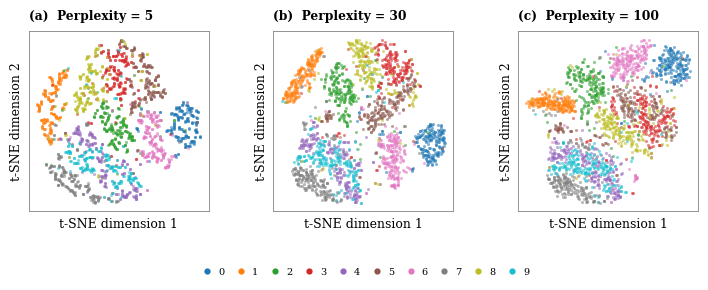

Saved PDF: /content/pictures/fig1_5_tsne_perplexity_mnist.pdf
Saved PNG: /content/pictures/fig1_5_tsne_perplexity_mnist.png


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from tensorflow.keras.datasets import mnist

(x_train, y_train), (_, _) = mnist.load_data()

rng = np.random.default_rng(42)
samples_per_class = 200
selected_indices = np.concatenate([rng.choice(np.flatnonzero(y_train == digit), samples_per_class, replace=False) for digit in range(10)])
rng.shuffle(selected_indices)

X_images = x_train[selected_indices]
y_tsne = y_train[selected_indices]
X_tsne = X_images.reshape(len(X_images), 784).astype(np.float32) / 255.0

pca_preprocess = PCA(n_components=50, svd_solver="randomized", random_state=42)
X_tsne_50d = pca_preprocess.fit_transform(X_tsne)

perplexities = [5, 30, 100]
panel_labels = ["(a)", "(b)", "(c)"]
DIGIT_COLORS = plt.cm.tab10(np.arange(10))

embeddings = []

for perplexity in perplexities:
    print(f"Running t-SNE with perplexity = {perplexity}...")
    tsne_model = TSNE(n_components=2, perplexity=perplexity, init="pca", learning_rate="auto", random_state=42)
    embedding = tsne_model.fit_transform(X_tsne_50d)
    embeddings.append(embedding)

fig = plt.figure(figsize=(7.2, 3.0))

panel_a = [0.035, 0.270, 0.250, 0.600]
panel_b = [0.375, 0.270, 0.250, 0.600]
panel_c = [0.715, 0.270, 0.250, 0.600]
panel_positions = [panel_a, panel_b, panel_c]

axes = [fig.add_axes(position) for position in panel_positions]

for ax, embedding, perplexity in zip(axes, embeddings, perplexities):
    for digit in range(10):
        mask = y_tsne == digit
        ax.scatter(embedding[mask, 0], embedding[mask, 1], color=DIGIT_COLORS[digit], s=5.0, alpha=0.55, linewidths=0, rasterized=True, zorder=3)
    ax.set_xlabel("t-SNE dimension 1")
    ax.set_ylabel("t-SNE dimension 2")
    ax.set_box_aspect(1.0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.spines["top"].set_color("0.55")
    ax.spines["right"].set_color("0.55")
    ax.spines["bottom"].set_color("0.55")
    ax.spines["left"].set_color("0.55")
    ax.spines["top"].set_linewidth(0.65)
    ax.spines["right"].set_linewidth(0.65)
    ax.spines["bottom"].set_linewidth(0.65)
    ax.spines["left"].set_linewidth(0.65)

panel_label_style = {"ha": "left", "va": "bottom", "fontsize": 8.8, "fontweight": "bold"}
fig.text(panel_a[0], 0.900, "(a)  Perplexity = 5", **panel_label_style)
fig.text(panel_b[0], 0.900, "(b)  Perplexity = 30", **panel_label_style)
fig.text(panel_c[0], 0.900, "(c)  Perplexity = 100", **panel_label_style)

digit_handles = [Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=DIGIT_COLORS[digit], markeredgecolor="none", markersize=4.5, label=str(digit)) for digit in range(10)]
fig.legend(handles=digit_handles, loc="lower center", bbox_to_anchor=(0.5, 0.025), ncol=10, frameon=False, handletextpad=0.15, columnspacing=0.70, fontsize=7.0)

output_dir = "/content/pictures"
os.makedirs(output_dir, exist_ok=True)
pdf_path = os.path.join(output_dir, "fig1_5_tsne_perplexity_mnist.pdf")
png_path = os.path.join(output_dir, "fig1_5_tsne_perplexity_mnist.png")

fig.savefig(pdf_path, dpi=600, bbox_inches=None, pad_inches=0)
fig.savefig(png_path, dpi=600, bbox_inches=None, pad_inches=0)
plt.show()

print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)


---

## 1.5. Tiếp cận giảm chiều bằng Diffusion Maps

**Diffusion Maps (DM)** khắc phục hạn chế của PCA bằng cách khai thác cấu trúc hình học của dữ liệu thông qua quá trình khuếch tán trên đồ thị. Độ tương đồng giữa các điểm dữ liệu được xác định bằng hàm nhân Gaussian:

$$
k(x_i,x_j)=\exp\left(-\frac{\|x_i-x_j\|^2}{\varepsilon}\right)
$$

Khoảng cách khuếch tán giữa hai điểm sau $t$ bước được xác định bởi:

$$
D_t^2(x_i,x_j)=
\sum_{k\geq 1}\lambda_k^{2t}
\left(\psi_k(x_i)-\psi_k(x_j)\right)^2
$$

Trong đó, $\lambda_k$ và $\psi_k$ lần lượt là trị riêng và hàm riêng của toán tử khuếch tán. Diffusion Maps có hai ưu điểm chính:

- **Bảo toàn cấu trúc lân cận:** Khai thác quan hệ hình học nội tại thay vì chỉ dựa trên phương sai toàn cục.
- **Biểu diễn đa thang đo:** Thời gian khuếch tán $t$ cho phép điều chỉnh mức độ chi tiết của cấu trúc dữ liệu.

Nhờ đó, Diffusion Maps có khả năng khai thác cả cấu trúc cục bộ và toàn cục của dữ liệu trong không gian giảm chiều.

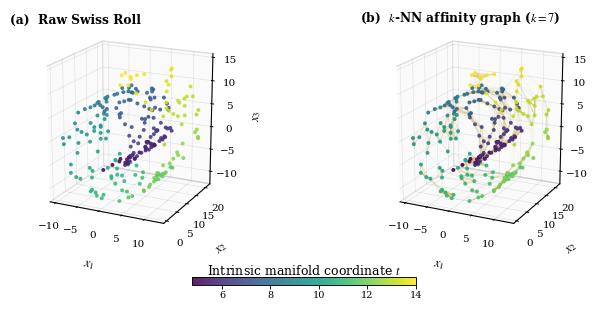

Dataset: Swiss Roll
Number of samples: 240
Ambient dimension: 3
Number of graph edges: 992
Saved PDF: /content/pictures/fig1_6_affinity_graph_swiss_roll.pdf
Saved PNG: /content/pictures/fig1_6_affinity_graph_swiss_roll.png


In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scipy.sparse as sp
from matplotlib.colors import Normalize
from sklearn.datasets import make_swiss_roll
from sklearn.neighbors import kneighbors_graph

K = 7
X_swiss, t_swiss = make_swiss_roll(n_samples=240, noise=0.08, random_state=42)

knn_graph = kneighbors_graph(X_swiss, n_neighbors=K, mode="connectivity", include_self=False)
knn_graph = knn_graph.maximum(knn_graph.T)
edge_graph = sp.triu(knn_graph, k=1).tocoo()

sq_distances = np.sum((X_swiss[edge_graph.row] - X_swiss[edge_graph.col]) ** 2, axis=1)
epsilon = np.median(sq_distances[sq_distances > 0])
edge_weights = np.exp(-sq_distances / epsilon)

time_norm = Normalize(vmin=float(t_swiss.min()), vmax=float(t_swiss.max()))
EDGE_STRONG = "#E69F00"
EDGE_WEAK = "#C2C2C2"

fig = plt.figure(figsize=(7.0, 3.0))

panel_a = [0.080, 0.240, 0.340, 0.660]
panel_b = [0.580, 0.240, 0.340, 0.660]

ax_raw = fig.add_axes(panel_a, projection="3d")
ax_graph = fig.add_axes(panel_b, projection="3d")

sc_raw = ax_raw.scatter(X_swiss[:, 0], X_swiss[:, 1], X_swiss[:, 2], c=t_swiss, cmap="viridis", norm=time_norm, s=8, alpha=0.88, linewidths=0, depthshade=False, rasterized=True)

for i, j, weight in zip(edge_graph.row, edge_graph.col, edge_weights):
    point_i = X_swiss[i]
    point_j = X_swiss[j]
    strength = float(weight)
    edge_color = (1.0 - strength) * np.array(mcolors.to_rgb(EDGE_WEAK)) + strength * np.array(mcolors.to_rgb(EDGE_STRONG))
    ax_graph.plot([point_i[0], point_j[0]], [point_i[1], point_j[1]], [point_i[2], point_j[2]], color=edge_color, alpha=0.12 + 0.55 * strength, linewidth=0.20 + 1.10 * strength, solid_capstyle="round", zorder=1)

ax_graph.scatter(X_swiss[:, 0], X_swiss[:, 1], X_swiss[:, 2], c=t_swiss, cmap="viridis", norm=time_norm, s=8, alpha=0.92, linewidths=0, depthshade=False, rasterized=True, zorder=3)

data_range = np.ptp(X_swiss, axis=0)
box_aspect = data_range / data_range.max()

for ax in [ax_raw, ax_graph]:
    try:
        ax.set_box_aspect(box_aspect, zoom=1.08)
    except TypeError:
        ax.set_box_aspect(box_aspect)
    ax.view_init(elev=18, azim=-64)
    ax.set_xlabel(r"$x_1$", labelpad=1.0)
    ax.set_ylabel(r"$x_2$", labelpad=1.0)
    ax.set_zlabel(r"$x_3$", labelpad=1.0)
    ax.tick_params(pad=0.3)
    for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
        axis.pane.fill = True
        axis.pane.set_facecolor((0.97, 0.97, 0.97, 1.0))
        axis.pane.set_edgecolor((0.74, 0.74, 0.74, 1.0))
        axis._axinfo["grid"].update({"color": (0.55, 0.55, 0.55, 0.25), "linewidth": 0.40})

panel_label_style = {"ha": "left", "va": "bottom", "fontsize": 8.8, "fontweight": "bold"}
fig.text(panel_a[0], 0.915, "(a)  Raw Swiss Roll", **panel_label_style)
fig.text(panel_b[0], 0.915, rf"(b)  $k$-NN affinity graph ($k={K}$)", **panel_label_style)

colorbar_axis = fig.add_axes([0.340, 0.055, 0.320, 0.025])
colorbar = fig.colorbar(sc_raw, cax=colorbar_axis, orientation="horizontal")
colorbar.ax.xaxis.set_label_position("top")
colorbar.set_label(r"Intrinsic manifold coordinate $t$", labelpad=2.0)
colorbar.ax.tick_params(labelsize=7.0, pad=1.5)
colorbar.outline.set_linewidth(0.65)

output_dir = "/content/pictures"
os.makedirs(output_dir, exist_ok=True)
pdf_path = os.path.join(output_dir, "fig1_6_affinity_graph_swiss_roll.pdf")
png_path = os.path.join(output_dir, "fig1_6_affinity_graph_swiss_roll.png")

fig.savefig(pdf_path, dpi=600, bbox_inches=None, pad_inches=0)
fig.savefig(png_path, dpi=600, bbox_inches=None, pad_inches=0)
plt.show()

print("Dataset: Swiss Roll")
print("Number of samples:", len(X_swiss))
print("Ambient dimension:", X_swiss.shape[1])
print("Number of graph edges:", len(edge_graph.data))
print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)
